### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [22]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [23]:
data = pd.read_csv("data/coupons.csv")

In [24]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [25]:
missing = data.isna().sum()
print(missing)
data.shape

destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64


(12684, 26)

3. Decide what to do about your missing data -- drop, replace, other...

In [26]:
# drop the car column as we'd lose most of the data if we dropna and the information contained in that column is superfluous 
data.drop(columns="car", inplace=True)
# if we dropna on the remaining null/nan values we lose 605 rows or ~5% of the data, the other option is to fillna with 'never' which would potentially skew understanding of the data
data.dropna(inplace=True)
data.shape

(12079, 25)

4. What proportion of the total observations chose to accept the coupon?



In [27]:
accepted = (data['Y'] == 1).mean() * 100
print(f"Total coupon acceptance rate: {accepted:.1f}% - ({(data['Y'] == 1).sum():,} out of {len(data):,})")

Total coupon acceptance rate: 56.9% - (6,877 out of 12,079)


5. Use a bar plot to visualize the `coupon` column.

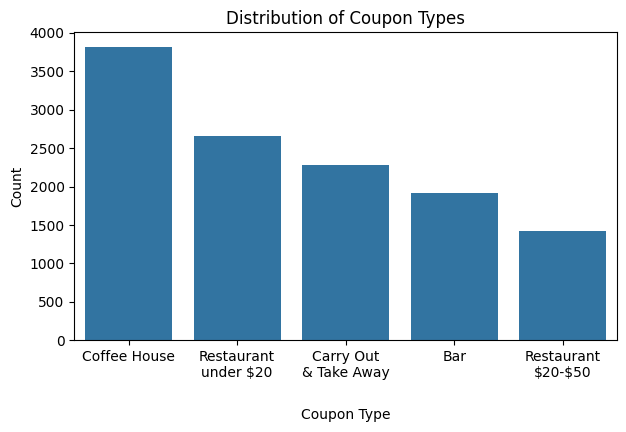

In [28]:
coupon_dict = {
    "Restaurant(<20)": "Restaurant\nunder $20",
    "Restaurant(20-50)": "Restaurant\n\\$20-\\$50",
    "Carry out & Take away": "Carry Out\n& Take Away"
    }

data["formatted_coupon"] = data["coupon"].replace(coupon_dict)

coupon_counts = data["formatted_coupon"].value_counts().reset_index()
coupon_counts.columns = ["formatted_coupon", "count"]

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x="formatted_coupon", y="count", data=coupon_counts)
ax.set_title("Distribution of Coupon Types")
ax.set_xlabel("Coupon Type", labelpad=20)
ax.set_ylabel("Count")
plt.savefig("images/coupon_distribution.png", bbox_inches="tight")


6. Use a histogram to visualize the temperature column.

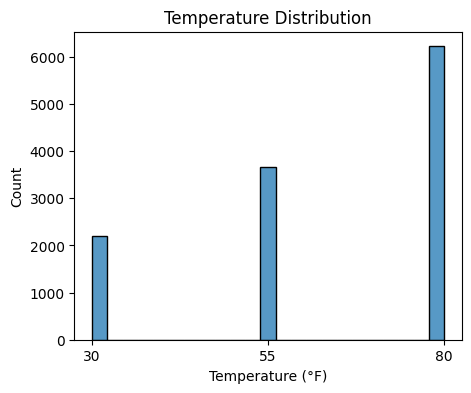

In [29]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.histplot(data=data, x="temperature", kde=False, ax=ax)
ax.set_title("Temperature Distribution")
ax.set_xlabel("Temperature (°F)")
ax.set_ylabel("Count")
ax.set_xticks([30, 55, 80])
plt.savefig("images/temperature_distribution.png", bbox_inches="tight")


**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [30]:
bar_coupons = data[data["coupon"] == "Bar"].copy()
bar_coupons.shape

(1913, 26)

2. What proportion of bar coupons were accepted?


Bar coupon acceptance rate: 41.2% - (788 out of 1913)


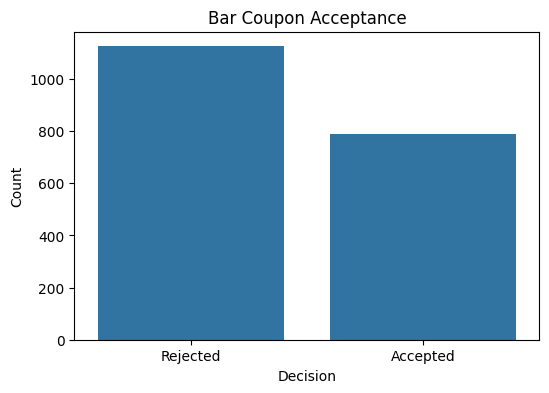

In [31]:
bar_acceptance_rate = (bar_coupons["Y"] == 1).mean() * 100
print(f"Bar coupon acceptance rate: {bar_acceptance_rate:.1f}% - ({(bar_coupons["Y"] == 1).sum()} out of {len(bar_coupons)})")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=bar_coupons, x="Y", ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Rejected", "Accepted"])
ax.set_title("Bar Coupon Acceptance")
ax.set_xlabel("Decision")
ax.set_ylabel("Count")
plt.savefig("images/bar_coupon_acceptance.png", bbox_inches="tight")


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


Acceptance rate for 3 or fewer bar visits/mo: 37.3%
Acceptance rate for 4+ bar visits/mo: 76.2%


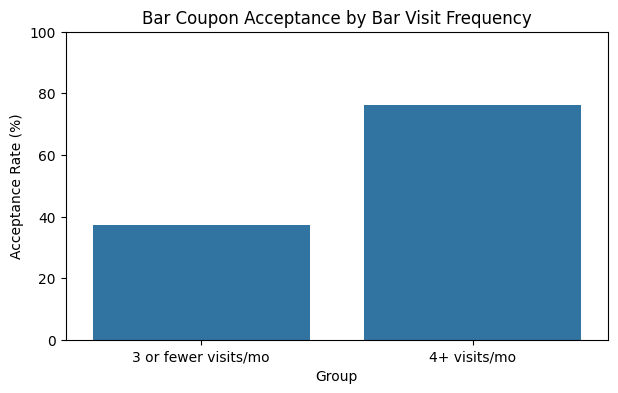

In [32]:
frequency_mask = bar_coupons["Bar"].isin(["4~8", "gt8"])

more_than_three = bar_coupons[frequency_mask]
three_or_less = bar_coupons[~frequency_mask]

more_than_three_rate = (more_than_three["Y"] == 1).mean() * 100
three_or_less_rate = (three_or_less["Y"] == 1).mean() * 100

print(f"Acceptance rate for 3 or fewer bar visits/mo: {three_or_less_rate:.1f}%")
print(f"Acceptance rate for 4+ bar visits/mo: {more_than_three_rate:.1f}%")

acceptance_comparison = pd.DataFrame({"Group": ["3 or fewer visits/mo", "4+ visits/mo"], "Acceptance Rate": [three_or_less_rate, more_than_three_rate]})
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=acceptance_comparison, x="Group", y="Acceptance Rate", ax=ax)
ax.set_title("Bar Coupon Acceptance by Bar Visit Frequency")
ax.set_ylabel("Acceptance Rate (%)")
ax.set_ylim(0, 100)
plt.savefig("images/bar_acceptance_by_frequency.png", bbox_inches="tight")


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


Acceptance rate for drivers who frequent bars at least once a month and are over 25: 69.0%
Acceptance rate for all the others: 33.8%


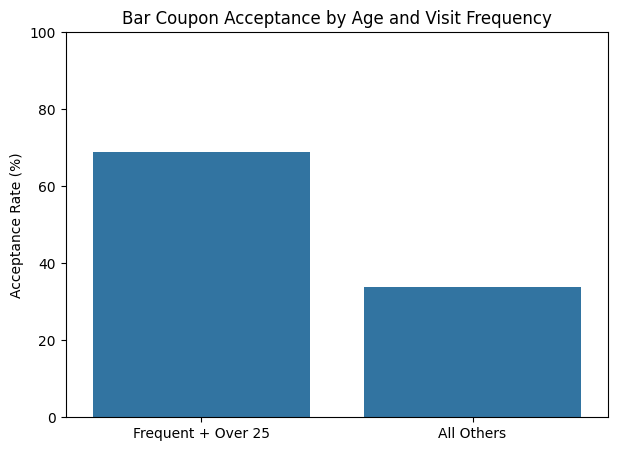

In [33]:
# clean the age data and convert to numbers
fix_age_dict = {"50plus": 50, "below21": 20}
bar_coupons["int_age"] = bar_coupons["age"].replace(fix_age_dict)
bar_coupons["int_age"] = bar_coupons["int_age"].astype(float)

mask = (bar_coupons["Bar"].isin(["1~3", "4~8", "gt8"])) & (bar_coupons["int_age"] > 25)
over_25 = bar_coupons[mask]
others = bar_coupons[~mask]

over_25_acceptance_rate = (over_25["Y"] == 1).mean() * 100
others_acceptance_rate = (others["Y"] == 1).mean() * 100

print(f"Acceptance rate for drivers who frequent bars at least once a month and are over 25: {over_25_acceptance_rate:.1f}%")
print(f"Acceptance rate for all the others: {others_acceptance_rate:.1f}%")

rates = pd.DataFrame({"Group": ["Frequent + Over 25", "All Others"], "Rate": [over_25_acceptance_rate, others_acceptance_rate]})
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=rates, x="Group", y="Rate", ax=ax)
ax.set_ylim(0, 100)
ax.set_title("Bar Coupon Acceptance by Age and Visit Frequency")
ax.set_ylabel("Acceptance Rate (%)")
ax.set_xlabel("")
plt.savefig("images/bar_acceptance_by_age_frequency.png", bbox_inches="tight")


Drivers over 25 who visit bars at least once a month show a 69% acceptance rate, compared to 34% for everyone else. This is consistent with our earlier finding that bar visit frequency is a strong indicator for acceptance; those who visit 4+ times a month have a 76% acceptance rate versus 37% for infrequent visitors. Adding the age filter further refines the picture, frequent bar goers over 25 accept at a higher rate than their younger counterparts, suggesting that established habits and age both play a role in coupon receptiveness.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


Acceptance rate for 1+/mo, with non-child passengers, and not in the farming/fishing/forestry industry: 70.9%
Acceptance rate for all the others: 29.8%


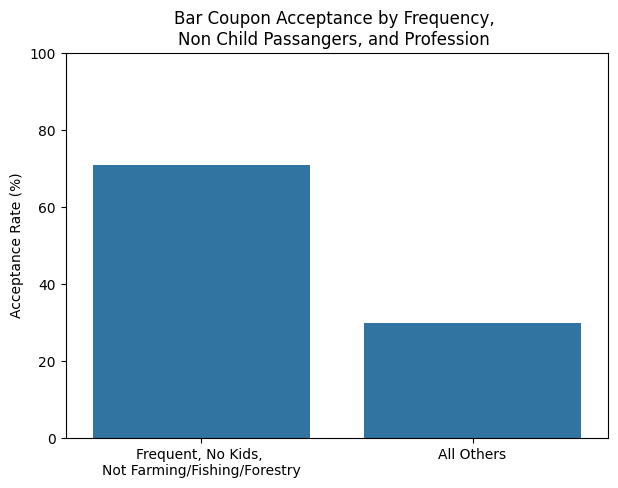

In [34]:
mask5 = (bar_coupons["Bar"].isin(["1~3", "4~8", "gt8"])) & (bar_coupons["passanger"] != "Kid(s)") & (bar_coupons["occupation"] != "Farming Fishing & Forestry")

# more than once a month with no child passengers who don't work in farming, fishing, or forestry
group_a = bar_coupons[mask5]
# every one not in group_a
group_b = bar_coupons[~mask5]

rate_a = (group_a["Y"] == 1).mean() * 100
rate_b = (group_b["Y"] == 1).mean() * 100

print(f"Acceptance rate for 1+/mo, with non-child passengers, and not in the farming/fishing/forestry industry: {rate_a:.1f}%")
print(f"Acceptance rate for all the others: {rate_b:.1f}%")

rates5 = pd.DataFrame({"Group": ["Frequent, No Kids, \nNot Farming/Fishing/Forestry", "All Others"], "Rate": [rate_a, rate_b]})

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=rates5, x="Group", y="Rate", ax=ax)
ax.set_ylim(0, 100)
ax.set_title("Bar Coupon Acceptance by Frequency, \nNon Child Passangers, and Profession ")
ax.set_ylabel("Acceptance Rate (%)")
ax.set_xlabel("")
plt.savefig("images/bar_acceptance_by_frequency_passengers_profession.png", bbox_inches="tight")


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



Combined acceptance rate for the 3 groups: 58.7%
Acceptance rate for everyone else: 30.0%
Acceptance rate for group1: freq 1+/mo, no child passengers, not widowed: 70.9%
Acceptance rate for group2: freq 1+/mo, age < 30y: 72.0%
Acceptance rate for group3: cheap restaurant 4+/mo, income < 50k: 45.6%


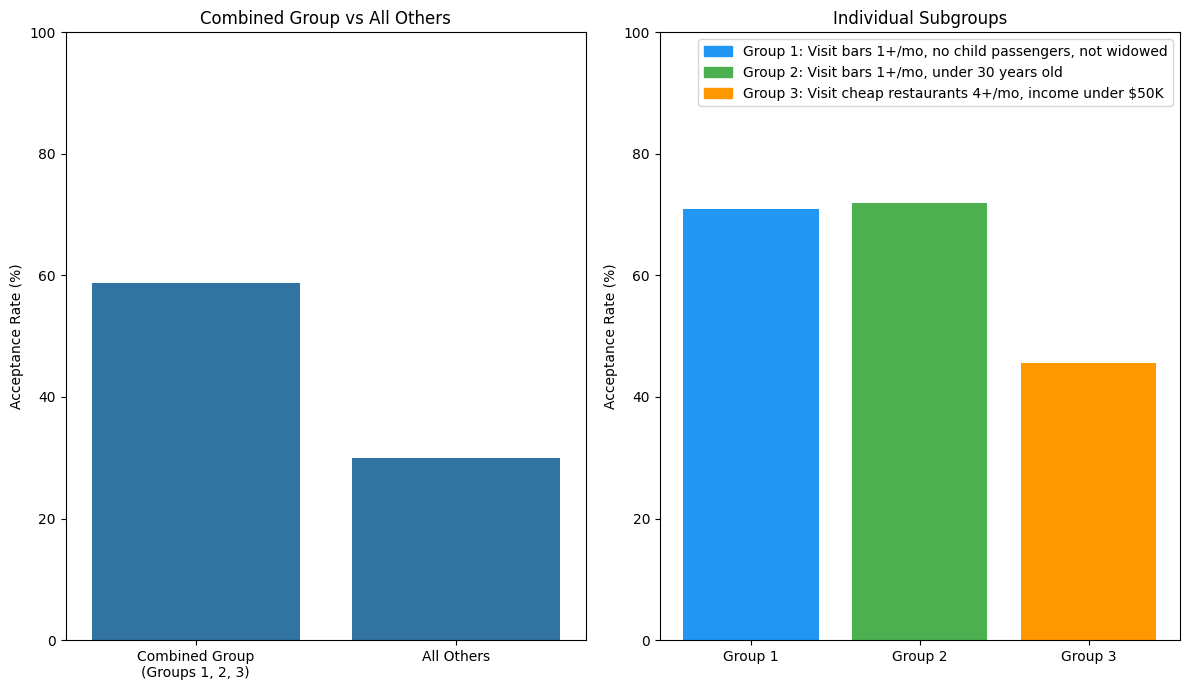

In [ ]:
mask6a = (bar_coupons["Bar"].isin(["1~3", "4~8", "gt8"])) & (bar_coupons["passanger"] != "Kid(s)") & (bar_coupons["maritalStatus"] != "Widowed")
mask6b = (bar_coupons["Bar"].isin(["1~3", "4~8", "gt8"])) & (bar_coupons["int_age"] < 30)
mask6c = (bar_coupons["RestaurantLessThan20"].isin(["4~8", "gt8"])) & (bar_coupons["income"].isin(["Less than $12500", "$12500 - $24999", "$25000 - $37499", "$37500 - $49999"]))

combined_mask6 = mask6a | mask6b | mask6c

target_group = bar_coupons[combined_mask6]
other_group = bar_coupons[~combined_mask6]

target_group_rate = (target_group["Y"] == 1).mean() * 100
other_group_rate = (other_group["Y"] == 1).mean() * 100

rate6a = (bar_coupons[mask6a]["Y"] == 1).mean() * 100
rate6b = (bar_coupons[mask6b]["Y"] == 1).mean() * 100
rate6c = (bar_coupons[mask6c]["Y"] == 1).mean() * 100

print(f"Combined acceptance rate for the 3 groups: {target_group_rate:.1f}%")
print(f"Acceptance rate for everyone else: {other_group_rate:.1f}%")
print(f"Acceptance rate for group1: freq 1+/mo, no child passengers, not widowed: {rate6a:.1f}%")
print(f"Acceptance rate for group2: freq 1+/mo, age < 30y: {rate6b:.1f}%")
print(f"Acceptance rate for group3: cheap restaurant 4+/mo, income < 50k: {rate6c:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 7))

combined_rates = pd.DataFrame({"Group": ["Combined Group\n(Groups 1, 2, 3)", "All Others"], "Rate": [target_group_rate, other_group_rate]})
sns.barplot(data=combined_rates, x="Group", y="Rate", ax=axes[0])
axes[0].set_ylim(0, 100)
axes[0].set_title("Combined Group vs All Others")
axes[0].set_ylabel("Acceptance Rate (%)")
axes[0].set_xlabel("")

x_pos = [0, 1, 2]
rates6 = [rate6a, rate6b, rate6c]
colors = ["#2196F3", "#4CAF50", "#FF9800"]

handles = [
    Patch(label="Group 1: Visit bars 1+/mo, no child passengers, not widowed", color=colors[0]),
    Patch(label="Group 2: Visit bars 1+/mo, under 30 years old", color=colors[1]),
    Patch(label="Group 3: Visit cheap restaurants 4+/mo, income under $50K", color=colors[2])
]

axes[1].bar(x_pos, rates6, color=colors)
axes[1].set_ylim(0, 100)
axes[1].set_title("Individual Subgroups")
axes[1].set_ylabel("Acceptance Rate (%)")
axes[1].set_xlabel("")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(["Group 1", "Group 2", "Group 3"])
axes[1].legend(handles=handles, loc="upper right", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.savefig("images/bar_acceptance_subgroups.png", bbox_inches="tight")


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Based on the above observations, we can hypothesize that drivers who are 25-30 years old, visit bars four or more times a month, and do not have children in the vehicle are the most likely to accept bar coupons. My analysis below shows this subgroup has a significantly higher acceptance rate (~84%) than the overall baseline (~41%).

Caveat: The sample size for this specific subgroup is small (n = 69, ~4% of bar coupon responses). We would need additional data to confirm this hypothesis with greater confidence.

Recommendation: Despite the small sample size, the strong signal suggests targeting bar coupons toward young adults (25-30) who are frequent bar goers and traveling without children. A focused marketing campaign or A/B test on this demographic could validate the finding at scale.

In [36]:
sweet_spot = bar_coupons.query("Bar in ['4~8', 'gt8'] & int_age >= 25 & int_age <= 30 & passanger != 'Kid(s)'")
age_25_30 = bar_coupons.query("int_age >= 25 & int_age <= 30")
no_kids = bar_coupons.query("passanger != 'Kid(s)'")

age_25_30_rate = (age_25_30["Y"] == 1).mean() * 100
no_kids_rate = (no_kids["Y"] == 1).mean() * 100
sweet_spot_rate = (sweet_spot["Y"] == 1).mean() * 100

total_accepted_bar_coupons = (bar_coupons["Y"] == 1).sum()

results = pd.DataFrame({
    "Filter Applied": [
        "All bar coupons",
        "Bar visits 4+ a month",
        "25 to 30 years old",
        "No children in car",
        "All three combined"
    ],
    "Acceptance Rate": [
        f"{bar_acceptance_rate:.1f}%",
        f"{more_than_three_rate:.1f}%",
        f"{age_25_30_rate:.1f}%",
        f"{no_kids_rate:.1f}%",
        f"{sweet_spot_rate:.1f}%"
    ],
    "Sample Size": [f"{n:,}" for n in [
        len(bar_coupons),
        len(bar_coupons[frequency_mask]),
        len(age_25_30),
        len(no_kids),
        len(sweet_spot)
    ]],
    "% of Total Accepted Bar Coupons": [
        "100%",
        f"{(more_than_three['Y'] == 1).sum() / total_accepted_bar_coupons * 100:.1f}%",
        f"{(age_25_30['Y'] == 1).sum() / total_accepted_bar_coupons * 100:.1f}%",
        f"{(no_kids['Y'] == 1).sum() / total_accepted_bar_coupons * 100:.1f}%",
        f"{(sweet_spot['Y'] == 1).sum() / total_accepted_bar_coupons * 100:.1f}%"
    ] 
})

results.set_index("Filter Applied")

,Acceptance Rate,Sample Size,% of Total Accepted Bar Coupons
Filter Applied,,,
All bar coupons,41.2%,"1,913",100%
Bar visits 4+ a month,76.2%,193,18.7%
25 to 30 years old,48.6%,368,22.7%
No children in car,43.5%,"1,719",94.9%
All three combined,84.1%,69,7.4%


### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

Overall coffee coupon acceptance rate: 49.6% - (1894/3816)


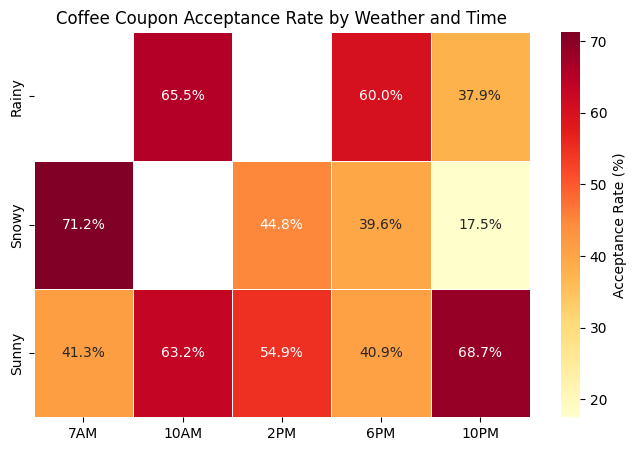

In [37]:
chrono_time = ["7AM", "10AM", "2PM", "6PM", "10PM"]
coffee = data[data["coupon"] == "Coffee House"].copy()
coffee_accept_rate = (coffee['Y'] == 1).mean() * 100

print(f"Overall coffee coupon acceptance rate: {coffee_accept_rate:.1f}% - ({(coffee['Y'] == 1).sum()}/{len(coffee)})")

pivot = coffee.pivot_table(index="weather", columns="time", values="Y", aggfunc="mean")
pivot = pivot[chrono_time]
annot_df = (pivot * 100).round(1).astype(str) + "%"

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot * 100, annot=annot_df, fmt="", cmap="YlOrRd", 
    linewidths=0.5, ax=ax, cbar_kws={"label": "Acceptance Rate (%)"})
ax.set_title("Coffee Coupon Acceptance Rate by Weather and Time")
ax.set_xlabel("")
ax.set_ylabel("")
plt.savefig("images/coffee_acceptance_weather_time.png", bbox_inches="tight")


Acceptance rate for less than 4 coffee house visits per month: 44.6%
Acceptance rate for 4 or more coffee house visits per month: 67.3%


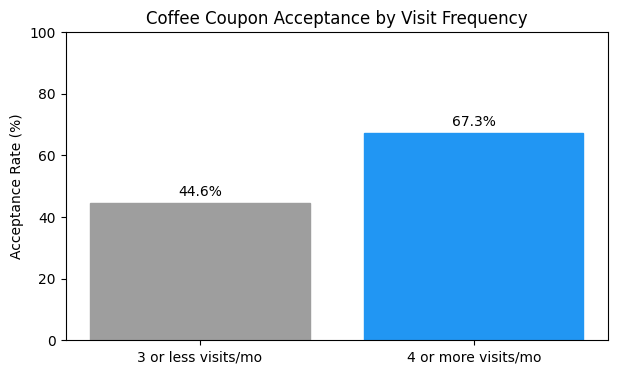

In [38]:
coffee_freq_mask = coffee["CoffeeHouse"].isin(["4~8", "gt8"])
frequent_coffee = coffee[coffee_freq_mask]
infrequent_coffee = coffee[~coffee_freq_mask]

frequent_coffee_rate = (frequent_coffee["Y"] == 1).mean() * 100
infrequent_coffee_rate = (infrequent_coffee["Y"] == 1).mean() * 100

print(f"Acceptance rate for less than 4 coffee house visits per month: {infrequent_coffee_rate:.1f}%")
print(f"Acceptance rate for 4 or more coffee house visits per month: {frequent_coffee_rate:.1f}%")

coffee_freq_rates = pd.DataFrame({
    "Group": ["3 or less visits/mo", "4 or more visits/mo"],
    "Rate": [infrequent_coffee_rate, frequent_coffee_rate]
})

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(coffee_freq_rates["Group"], coffee_freq_rates["Rate"])
ax.set_ylim(0, 100)
ax.set_title("Coffee Coupon Acceptance by Visit Frequency")
ax.set_ylabel("Acceptance Rate (%)")
ax.set_xlabel("")

bars[0].set_color("#9E9E9E")
bars[1].set_color("#2196F3")
for bar in bars:
    ax.annotate(f"{bar.get_height():.1f}%",
    (bar.get_x() + bar.get_width()/2, bar.get_height()),
    ha="center", va="bottom", xytext=(0, 3),
    textcoords="offset points")
plt.savefig("images/coffee_acceptance_by_frequency.png", bbox_inches="tight")


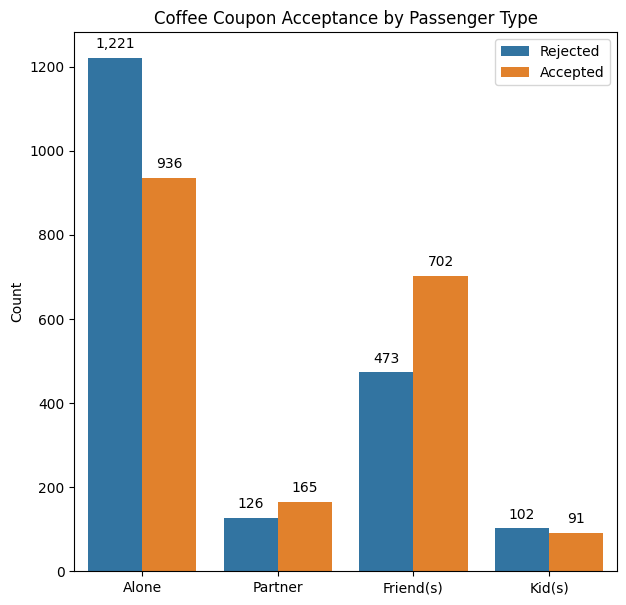

In [39]:
passangers = ["Alone", "Partner", "Friend(s)", "Kid(s)"]

fig, ax = plt.subplots(figsize=(7, 7))
sns.countplot(x="passanger", hue="Y", data=coffee, ax=ax, hue_order=[0,1], order=passangers)
ax.legend(labels=["Rejected", "Accepted"])
ax.set_title("Coffee Coupon Acceptance by Passenger Type")
ax.set_ylabel("Count")
ax.set_xlabel("")

for p in ax.patches:
    count = int(p.get_height())
    # had a mysterious 0 in the plot
    if count > 0:
        ax.annotate(f"{count:,}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center", va="bottom", xytext=(0, 5), textcoords="offset points")
plt.savefig("images/coffee_acceptance_by_passenger.png", bbox_inches="tight")


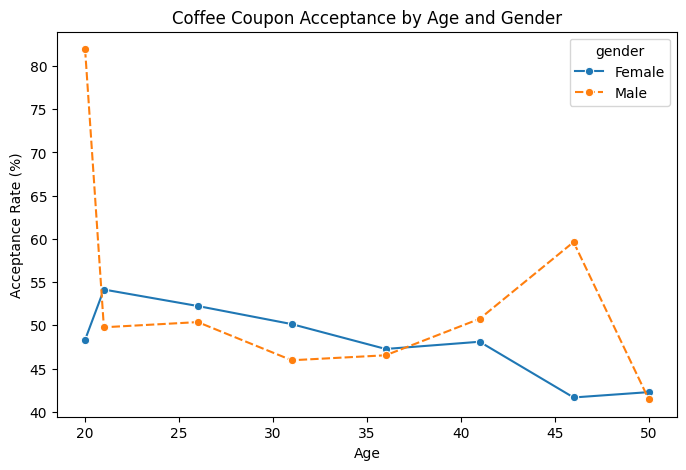

In [40]:
coffee["int_age"] = coffee["age"].replace({"50plus": 50, "below21": 20})
coffee["int_age"] = coffee["int_age"].astype(float)
age_pivot = coffee.pivot_table(index="int_age", columns="gender", values="Y", aggfunc=lambda x: x.mean() * 100)

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=age_pivot, marker="o", ax=ax)
ax.set_title("Coffee Coupon Acceptance by Age and Gender")
ax.set_xlabel("Age")
ax.set_ylabel("Acceptance Rate (%)")
plt.savefig("images/coffee_acceptance_by_age_gender.png", bbox_inches="tight")


Based on the above observations, we can hypothesize that drivers who have friends as passengers, frequently visit coffee houses, and are offered coupons during morning hours under inclement weather are the most likely to accept coffee coupons. My analysis below shows this hypothesis group has a significantly higher acceptance rate (~86%) than the overall baseline (~50%).

Caveat: The survey data never generated scenarios with friends in the car during rainy or snowy weather (all friend scenarios were on sunny days), so these two morning contexts cannot be combined into a single intersection (n = 0). However, treating them as complementary morning target groups still yields a reliable sample size (n = 229, ~10% of total accepted coffee coupons) with high acceptance rates (88% with friends, 81% in inclement weather).

Recommendation: Target morning coffee coupons (7AM–10AM) toward frequent coffee drinkers using contextual triggers: deliver promotions when friends are in the car, and trigger weather-based promotions during rain or snow to capture morning commuters looking for a warm drink.

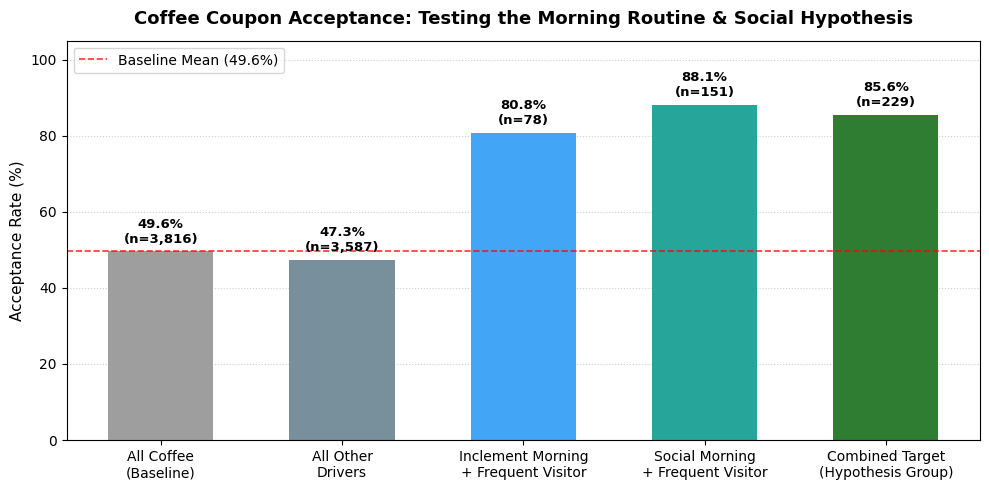

,Acceptance Rate,Sample Size (N),% of Total Accepted
Cohort / Scenario,,,
All Coffee Coupons (Baseline),49.6%,"3,816",100.0%
Social Morning (Friends + Frequent + Morning),88.1%,151,7.0%
Inclement Morning (Rain/Snow + Frequent + Morning),80.8%,78,3.3%
Combined Target Group (Social OR Inclement Morning),85.6%,229,10.3%
All Other Coffee Drivers,47.3%,"3,587",89.7%


In [ ]:
freq_coffee_mask = coffee["CoffeeHouse"].isin(["1~3", "4~8", "gt8"])
social_morning_mask = (coffee["passanger"] == "Friend(s)") & (coffee["time"].isin(["7AM", "10AM"])) & freq_coffee_mask
inclement_morning_mask = (coffee["weather"].isin(["Rainy", "Snowy"])) & (coffee["time"].isin(["7AM", "10AM"])) & freq_coffee_mask

hypothesis_target_mask = social_morning_mask | inclement_morning_mask
other_drivers_mask = ~hypothesis_target_mask

baseline_rate = (coffee["Y"] == 1).mean() * 100
social_rate = (coffee[social_morning_mask]["Y"] == 1).mean() * 100
inclement_rate = (coffee[inclement_morning_mask]["Y"] == 1).mean() * 100
target_rate = (coffee[hypothesis_target_mask]["Y"] == 1).mean() * 100
others_rate = (coffee[other_drivers_mask]["Y"] == 1).mean() * 100

total_accepted = (coffee["Y"] == 1).sum()
social_accepted = (coffee[social_morning_mask]["Y"] == 1).sum()
inclement_accepted = (coffee[inclement_morning_mask]["Y"] == 1).sum()
target_accepted = (coffee[hypothesis_target_mask]["Y"] == 1).sum()
others_accepted = (coffee[other_drivers_mask]["Y"] == 1).sum()

plot_df = pd.DataFrame({
    "Cohort": [
        "All Coffee\n(Baseline)",
        "All Other\nDrivers",
        "Inclement Morning\n+ Frequent Visitor",
        "Social Morning\n+ Frequent Visitor",
        "Combined Target\n(Hypothesis Group)"
    ],
    "Acceptance Rate": [baseline_rate, others_rate, inclement_rate, social_rate, target_rate],
    "Sample Size": [len(coffee), other_drivers_mask.sum(), inclement_morning_mask.sum(), social_morning_mask.sum(), hypothesis_target_mask.sum()]
})

bar_colors = ["#9E9E9E", "#78909C", "#42A5F5", "#26A69A", "#2E7D32"]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(plot_df["Cohort"], plot_df["Acceptance Rate"], color=bar_colors, width=0.58, zorder=2)
ax.axhline(baseline_rate, color="red", linestyle="--", linewidth=1.2, alpha=0.8, label=f"Baseline Mean ({baseline_rate:.1f}%)")

ax.set_ylim(0, 105)
ax.set_ylabel("Acceptance Rate (%)", fontsize=11)
ax.set_title("Coffee Coupon Acceptance: Testing the Morning Routine & Social Hypothesis", fontsize=13, fontweight="bold", pad=12)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(loc="upper left")

for bar, n in zip(bars, plot_df["Sample Size"]):
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%\n(n={n:,})",
                (bar.get_x() + bar.get_width() / 2, h),
                ha="center", va="bottom", xytext=(0, 4),
                textcoords="offset points", fontsize=9.5, fontweight="bold")

plt.tight_layout()
plt.savefig("images/coffee_hypothesis_test.png", bbox_inches="tight")
plt.show()

hypothesis_summary = pd.DataFrame({
    "Cohort / Scenario": [
        "All Coffee Coupons (Baseline)",
        "Social Morning (Friends + Frequent + Morning)",
        "Inclement Morning (Rain/Snow + Frequent + Morning)",
        "Combined Target Group (Social OR Inclement Morning)",
        "All Other Coffee Drivers"
    ],
    "Acceptance Rate": [
        f"{baseline_rate:.1f}%",
        f"{social_rate:.1f}%",
        f"{inclement_rate:.1f}%",
        f"{target_rate:.1f}%",
        f"{others_rate:.1f}%"
    ],
    "Sample Size (N)": [
        f"{len(coffee):,}",
        f"{social_morning_mask.sum():,}",
        f"{inclement_morning_mask.sum():,}",
        f"{hypothesis_target_mask.sum():,}",
        f"{other_drivers_mask.sum():,}"
    ],
    "% of Total Accepted": [
        "100.0%",
        f"{social_accepted / total_accepted * 100:.1f}%",
        f"{inclement_accepted / total_accepted * 100:.1f}%",
        f"{target_accepted / total_accepted * 100:.1f}%",
        f"{others_accepted / total_accepted * 100:.1f}%"
    ]
})

hypothesis_summary.set_index("Cohort / Scenario")


Overall Coffee Coupon Acceptance Rate: 49.6% (N = 3,816)
Identified 21 predictor features to analyze.


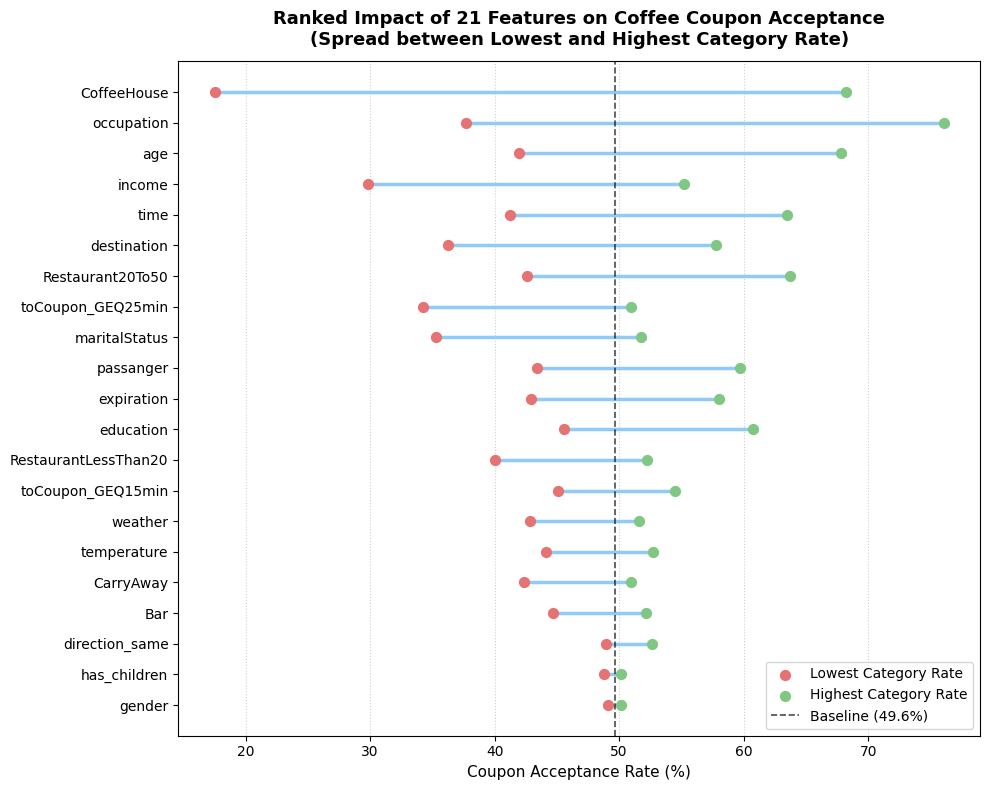

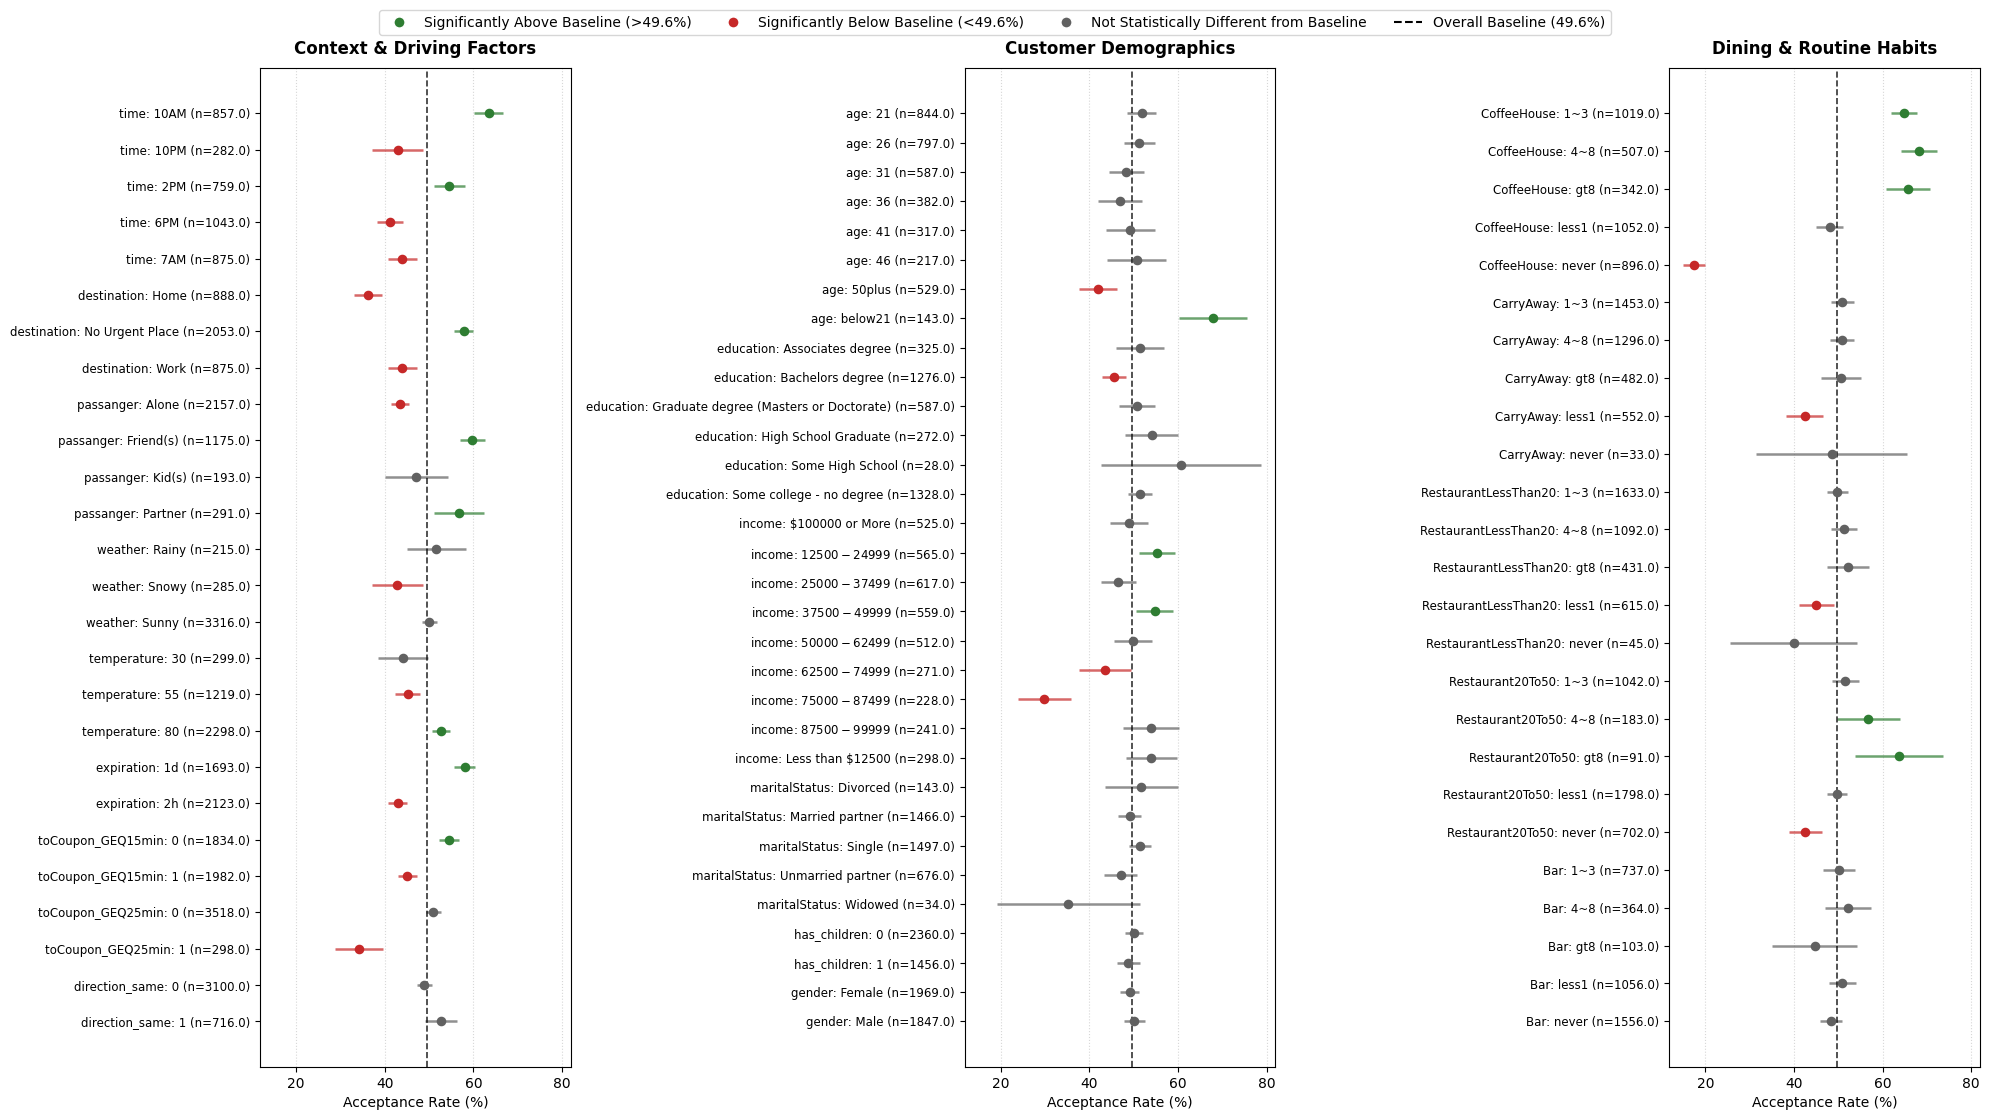

In [ ]:
# Deeper dive into coffee coupons - for the fun of it
overall_rate = coffee["Y"].mean() * 100
total_n = len(coffee)
print(f"Overall Coffee Coupon Acceptance Rate: {overall_rate:.1f}% (N = {total_n:,})")

ignore_cols = ["coupon", "toCoupon_GEQ5min", "direction_opp", "Y", "int_age", "formatted_coupon"]
feature_cols = [c for c in coffee.columns if c not in ignore_cols]
print(f"Identified {len(feature_cols)} predictor features to analyze.")

spreads = []
for col in feature_cols:
    rates = coffee.groupby(col)["Y"].mean() * 100
    spreads.append({
        "Feature": col,
        "Min Rate": rates.min(),
        "Max Rate": rates.max(),
        "Spread": rates.max() - rates.min(),
        "Best Group": str(rates.idxmax()),
        "Worst Group": str(rates.idxmin())
    })

df_spreads = pd.DataFrame(spreads).sort_values(by="Spread", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 8))
for i, row in df_spreads.iterrows():
    ax.hlines(y=i, xmin=row["Min Rate"], xmax=row["Max Rate"], color="#90CAF9", linewidth=2.5, zorder=2)
    ax.scatter(row["Min Rate"], i, color="#E57373", s=50, zorder=3, label="Lowest Category Rate" if i == 0 else "")
    ax.scatter(row["Max Rate"], i, color="#81C784", s=50, zorder=3, label="Highest Category Rate" if i == 0 else "")

ax.axvline(overall_rate, color="black", linestyle="--", linewidth=1.2, alpha=0.7, label=f"Baseline ({overall_rate:.1f}%)")
ax.set_yticks(range(len(df_spreads)))
ax.set_yticklabels(df_spreads["Feature"], fontsize=10)
ax.set_xlabel("Coupon Acceptance Rate (%)", fontsize=11)
ax.set_title("Ranked Impact of 21 Features on Coffee Coupon Acceptance\n(Spread between Lowest and Highest Category Rate)", fontsize=13, fontweight="bold", pad=12)
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/coffee_feature_impact_forest_plot.png", bbox_inches="tight")
plt.show()

context_cols = ["time", "destination", "passanger", "weather", "temperature", "expiration", "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same"]
demographics_cols = ["age", "education", "income", "maritalStatus", "has_children", "gender"]
habits_cols = ["CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50", "Bar"]

def calculate_subgroup_cis(cols):
    records = []
    for col in cols:
        grouped = coffee.groupby(col)["Y"].agg(["count", "mean"])
        for val, row in grouped.iterrows():
            n = row["count"]
            p = row["mean"] * 100
            # Binomial standard error converted to percent
            se = np.sqrt((p / 100) * (1 - p / 100) / n) * 100 if n > 0 else 0
            ci_lower = max(0, p - 1.96 * se)
            ci_upper = min(100, p + 1.96 * se)
            
            if ci_lower > overall_rate:
                color = "#2E7D32"
            elif ci_upper < overall_rate:
                color = "#C62828"
            else:
                color = "#616161"
                
            records.append({
                "Feature": col,
                "Label": f"{col}: {val} (n={n})",
                "Rate": p,
                "CI_Lower": ci_lower,
                "CI_Upper": ci_upper,
                "Color": color
            })
    return pd.DataFrame(records).iloc[::-1].reset_index(drop=True)

panels = [
    ("Context & Driving Factors", calculate_subgroup_cis(context_cols)),
    ("Customer Demographics", calculate_subgroup_cis(demographics_cols)),
    ("Dining & Routine Habits", calculate_subgroup_cis(habits_cols))
]

fig, axes = plt.subplots(1, 3, figsize=(20, 11), sharex=True)

for ax, (title, df_panel) in zip(axes, panels):
    y_pos = range(len(df_panel))
    
    # Draw 95% CI error bars and point estimates
    for y, (_, row) in zip(y_pos, df_panel.iterrows()):
        ax.hlines(y=y, xmin=row["CI_Lower"], xmax=row["CI_Upper"], color=row["Color"], linewidth=1.8, alpha=0.7)
        ax.scatter(row["Rate"], y, color=row["Color"], s=35, zorder=3)
        
    ax.axvline(overall_rate, color="black", linestyle="--", linewidth=1.2, alpha=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_panel["Label"], fontsize=8.5)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Acceptance Rate (%)", fontsize=10)
    ax.grid(axis="x", linestyle=":", alpha=0.5)

custom_handles = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#2E7D32", markersize=8, label="Significantly Above Baseline (>49.6%)"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#C62828", markersize=8, label="Significantly Below Baseline (<49.6%)"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#616161", markersize=8, label="Not Statistically Different from Baseline"),
    plt.Line2D([0], [0], color="black", linestyle="--", label=f"Overall Baseline ({overall_rate:.1f}%)")
]
fig.legend(handles=custom_handles, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig("images/coffee_subgroups_forest_plot.png", bbox_inches="tight")
plt.show()
